# EUV multilayers and reflective masks

At 13.5 nm every material absorbs, and every refractive index is within a
few percent of one. There are no lenses: EUV scanners image a reflective
mask with mirrors, and each mirror reflects through a multilayer of about
40 pairs of molybdenum and silicon. The weak reflections at the 80
interfaces add up in phase to about 70 %. This notebook builds the two
reflective parts on a mask and wafer simulation that otherwise stays the
DUV one of notebook 31 (vectorial imaging in lithography):

- **Multilayer mirrors** (`litho.euv.Multilayer`): reflectance over the
  number of pairs, the wavelength and the angle, capping layer and
  interlayers, and the depth of the plane the reflection appears to come
  from. The thin film code is that of notebook 10 (interfaces and thin films).
- **The multilayer over the pupil**: every source point and diffraction
  order meets the mask blank at its own angle, so the blank acts as an
  apodization, a phase and a weak diattenuator, a Jones pupil as in
  notebook 38 (Jones pupils).
- **The reflective mask** (`litho.euv.ReflectiveMask`): an absorber
  (TaBN, or a low-n material) patterned on the multilayer, lit at a chief
  ray angle (CRA) of 6°. The reflected orders come from the RCWA of
  notebook 36 (rigorous mask), which now handles the 81 plane layers of
  the blank order by order. The oblique light gives the mask 3D effects
  that set EUV apart: shadowing that depends on the orientation of the
  lines, a best focus that changes with the pitch, a shift of the pattern
  and a telecentricity error.

Notebook 157 (EUV projector and pupil) continues with the projection
optics, the anamorphic high-NA projector and the obscured pupil, notebook
158 (EUV stochastics and flare) with the photons and the scattered light.

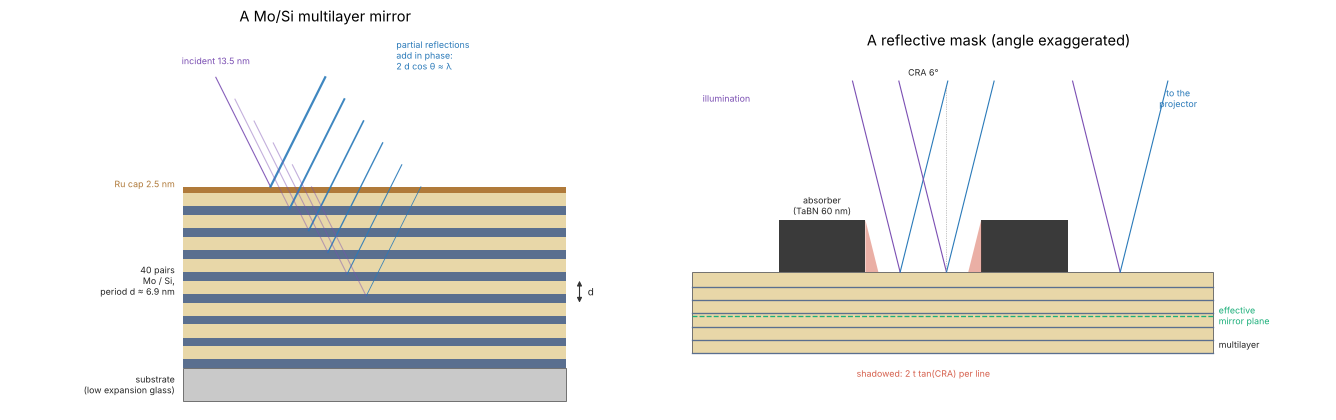

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import sketch
from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, euv, jones_pupil, metrics

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()
BLUE, ORANGE, GREEN, YELLOW, RED, PURPLE, GREY = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#d03b3b",
                                                  "#8a5cc2", "#888888")
LAM = euv.EUV_WAVELENGTH
DEG = np.pi/180

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
sketch.euv_layout(axes[0], "multilayer", title="A Mo/Si multilayer mirror")
sketch.euv_layout(axes[1], "mask", title="A reflective mask (angle exaggerated)")
fig.tight_layout()

## 1. Optical constants at 13.5 nm

EUV optical constants are written $n = 1 - \delta + i\beta$; the table
lists them for the materials of this notebook (Henke tables, as CXRO gives
them). A single surface reflects less than half a percent at normal
incidence, and the absorption lengths $\lambda/(4\pi k)$ are tens to
hundreds of nanometres: no material makes a mirror on its own, and nothing
transmits through more than a fraction of a micrometre.

In [2]:
print("material      n        k     delta    absorption length   R (normal, from vacuum)")
for name in ("Mo", "Si", "Ru", "MoSi2", "SiO2", "TaBN", "TaBO", "Ni", "low-n"):
    N = euv.INDEX_13_5[name]
    print(f"{name:8s}  {N.real:.4f}  {N.imag:.5f}  {1 - N.real:.4f}   {LAM/(4*np.pi*N.imag):7.1f} nm"
          f"        {100*abs((1 - N)/(1 + N))**2:.3f} %")
r_mo_si = (euv.INDEX_13_5["Si"] - euv.INDEX_13_5["Mo"])/(euv.INDEX_13_5["Si"] + euv.INDEX_13_5["Mo"])
print(f"\nMo/Si interface: |r| = {abs(r_mo_si):.4f}, R = {100*abs(r_mo_si)**2:.3f} %; "
      f"2 x 40 interfaces in phase: |r| up to {80*abs(r_mo_si):.2f}")

material      n        k     delta    absorption length   R (normal, from vacuum)
Mo        0.9238  0.00644  0.0762     166.8 nm        0.158 %
Si        0.9990  0.00183  0.0010     587.0 nm        0.000 %
Ru        0.8864  0.01706  0.1136      63.0 nm        0.371 %
MoSi2     0.9689  0.00434  0.0311     247.5 nm        0.025 %
SiO2      0.9780  0.01080  0.0220      99.5 nm        0.015 %
TaBN      0.9490  0.03100  0.0510      34.7 nm        0.094 %
TaBO      0.9520  0.02600  0.0480      41.3 nm        0.078 %
Ni        0.9483  0.07270  0.0517      14.8 nm        0.209 %
low-n     0.9000  0.03000  0.1000      35.8 nm        0.302 %

Mo/Si interface: |r| = 0.0392, R = 0.154 %; 2 x 40 interfaces in phase: |r| up to 3.13


Molybdenum and silicon are the best pair at 13.5 nm: the largest contrast in
$\delta$ (0.076 against 0.001) with little absorption, silicon being almost
transparent just above its L edge at 12.4 nm. One Mo/Si interface reflects
only 0.15 % of the power, an amplitude of 0.04. Eighty interfaces whose
reflections add in phase would give an amplitude above one; absorption
caps the useful depth long before.

## 2. The Mo/Si multilayer

`Multilayer.design()` finds the period that puts the peak at 13.5 nm for
6°. The period is close to $\lambda/(2\cos\theta)$, slightly longer
because $n < 1$ in the stack. Panels: the reflectance as pairs are added,
the band of wavelengths and of angles, and the share $\Gamma$ of
molybdenum in the period.

Multilayer(40 x 6.942 nm, gamma=0.40, capping=('Ru', 2.5)) R = 73.4 %
Multilayer(40 x 6.947 nm, gamma=0.40, capping=('Ru', 2.5)) R = 71.9 %  (with interlayers)
no cap: R = 72.6 %


R falls to half its peak at 12.1° and is 73 % at normal incidence; R_s - R_p at 20°: 4.1 %
best Γ: 0.42
ten mirrors at 72 %: 3.7 % transmission


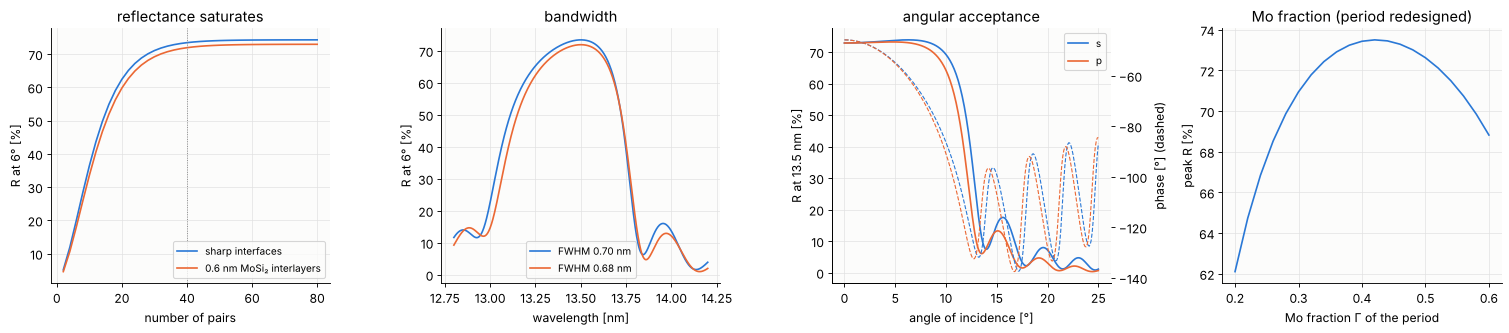

In [3]:
ml = euv.Multilayer.design(LAM, 6*DEG)                    # 40 pairs, Ru cap, gamma 0.4
ml_il = euv.Multilayer.design(LAM, 6*DEG, interlayer=0.6)  # with 0.6 nm MoSi2 at every interface
print(ml, f"R = {100*ml.reflectance(6*DEG):.1f} %")
print(ml_il, f"R = {100*ml_il.reflectance(6*DEG):.1f} %  (with interlayers)")
print(f"no cap: R = {100*ml.with_(capping=None).reflectance(6*DEG):.1f} %")

pairs = np.arange(2, 81, 2)
R_pairs = [ml.with_(pairs=p).reflectance(6*DEG) for p in pairs]
R_pairs_il = [ml_il.with_(pairs=p).reflectance(6*DEG) for p in pairs]
lam = np.linspace(12.8, 14.2, 561)
R_lam = ml.reflectance(6*DEG, lam)
R_lam_il = ml_il.reflectance(6*DEG, lam)
ang = np.linspace(0, 25, 251)*DEG
r_s, r_p = ml.amplitudes(ang)
gammas = np.linspace(0.2, 0.6, 21)
R_gamma = [euv.Multilayer.design(LAM, 6*DEG, gamma=g).reflectance(6*DEG) for g in gammas]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
ax = axes[0]
ax.plot(pairs, 100*np.array(R_pairs), color=BLUE, label="sharp interfaces")
ax.plot(pairs, 100*np.array(R_pairs_il), color=ORANGE, label="0.6 nm MoSi₂ interlayers")
ax.axvline(40, color="0.5", ls=":", lw=0.8)
ax.set_xlabel("number of pairs"); ax.set_ylabel("R at 6° [%]"); ax.legend(fontsize=9)
ax.set_title("reflectance saturates")
ax = axes[1]
ax.plot(lam, 100*R_lam, color=BLUE, label=f"FWHM {euv.fwhm(lam, R_lam):.2f} nm")
ax.plot(lam, 100*R_lam_il, color=ORANGE, label=f"FWHM {euv.fwhm(lam, R_lam_il):.2f} nm")
ax.set_xlabel("wavelength [nm]"); ax.set_ylabel("R at 6° [%]"); ax.legend(fontsize=9)
ax.set_title("bandwidth")
ax = axes[2]
ax.plot(ang/DEG, 100*abs(r_s)**2, color=BLUE, label="s")
ax.plot(ang/DEG, 100*abs(r_p)**2, color=ORANGE, label="p")
ax2 = ax.twinx()
ax2.plot(ang/DEG, np.unwrap(np.angle(r_s))/DEG, color=BLUE, ls="--", lw=1)
ax2.plot(ang/DEG, np.unwrap(np.angle(r_p))/DEG, color=ORANGE, ls="--", lw=1)
ax2.set_ylabel("phase [°] (dashed)"); ax2.grid(False)
ax.set_xlabel("angle of incidence [°]"); ax.set_ylabel("R at 13.5 nm [%]"); ax.legend(fontsize=9)
ax.set_title("angular acceptance")
ax = axes[3]
ax.plot(gammas, 100*np.array(R_gamma), color=BLUE)
ax.set_xlabel("Mo fraction Γ of the period"); ax.set_ylabel("peak R [%]")
ax.set_title("Mo fraction (period redesigned)")
fig.tight_layout()

R_ang = (abs(r_s)**2 + abs(r_p)**2)/2
print(f"R falls to half its peak at {ang[np.nonzero(R_ang > R_ang.max()/2)[0][-1]]/DEG:.1f}° "
      f"and is {100*R_ang[0]:.0f} % at normal incidence; "
      f"R_s - R_p at 20°: {100*(abs(r_s[200])**2 - abs(r_p[200])**2):.1f} %")
print(f"best Γ: {gammas[np.argmax(R_gamma)]:.2f}")
print(f"ten mirrors at {100*ml_il.reflectance(6*DEG):.0f} %: {100*ml_il.reflectance(6*DEG)**10:.1f} % "
      f"transmission")

- **Saturation.** The reflectance stops growing after about 40 pairs
  (280 nm), the depth from which absorption lets the light come back. More
  pairs only narrow the band a little. Real mirrors reach about 70 %,
  slightly below the ideal 73 %, because molybdenum and silicon mix at
  the interfaces. 0.6 nm of MoSi₂ on each side costs 1.5 points here;
  roughness costs more. The ruthenium cap protects the stack from
  oxidation and costs less than a point.
- **Bandwidth.** About 0.7 nm FWHM (5 %), the relative bandwidth set by the
  number of periods that take part. The optical constants of 13.5 nm are
  kept over the whole band (silicon has its L edge at 12.4 nm), so the
  skirts are approximate. With about ten mirrors in illuminator and
  projector (0.72¹⁰ ≈ 3.7 %), all of them must sit on the same wavelength
  to a few hundredths of a nanometre.
- **Angles.** The reflectance holds up to about 9° and falls to half at
  12°, and s and p differ by a few percent there (the Brewster angle is
  near 45°, far away). The phase changes with the angle, which section 3
  turns into an effective mirror plane. A mirror whose angles of
  incidence vary over more than a few degrees needs a period that
  varies across its surface (graded, notebook 157, EUV projector and pupil).
- **Γ.** About 0.4: less molybdenum absorbs less, more gives more
  contrast.

## 3. The multilayer over the pupil: apodization, phase and an effective mirror plane

Each source point lights the mask from its own direction, the chief ray
direction plus $\mathrm{NA}\,\sigma/M$, and each order leaves it in its
own. The blank multiplies the field of every plane wave by its
reflection: by $r_s$ for the component perpendicular to the plane of
incidence and $r_p$ for the one in it (`Multilayer.jones()`). Over the
mask-side cone this is a Jones pupil. `jones_pupil.decompose()` splits it into
the reflectance (apodization), a scalar phase and diattenuation and
retardance.

The phase grows with the angle as if the light were reflected by a plain
mirror inside the stack, $\phi(\theta) \approx \phi_0 + 2kz_\mathrm{eff}\cos\theta$:
`Multilayer.effective_depth()` gives that depth. It matters for the
mask: the absorber sits on top, the effective mirror tens of nanometres below
it.

effective mirror plane 46.4 nm below the top of the stack (s), 50.0 nm (p); the stack is 280 nm thick


NA 0.33, 4x, CRA 6°: reflectance 0.846 to 1.000 of the chief ray, phase Zernikes Z2..Z9 [waves]: -0.000 -0.068 -0.015 +0.005 +0.000 -0.000 -0.003 -0.001


NA 0.55, 4x, CRA 9°: reflectance 0.106 to 1.000 of the chief ray, phase Zernikes Z2..Z9 [waves]: -0.000 -0.154 -0.027 -0.019 +0.000 -0.000 +0.032 +0.018


NA 0.55, 4x/8x, CRA 5.355°: reflectance 0.879 to 1.000 of the chief ray, phase Zernikes Z2..Z9 [waves]: -0.000 -0.051 -0.025 -0.027 +0.000 -0.000 -0.003 -0.001


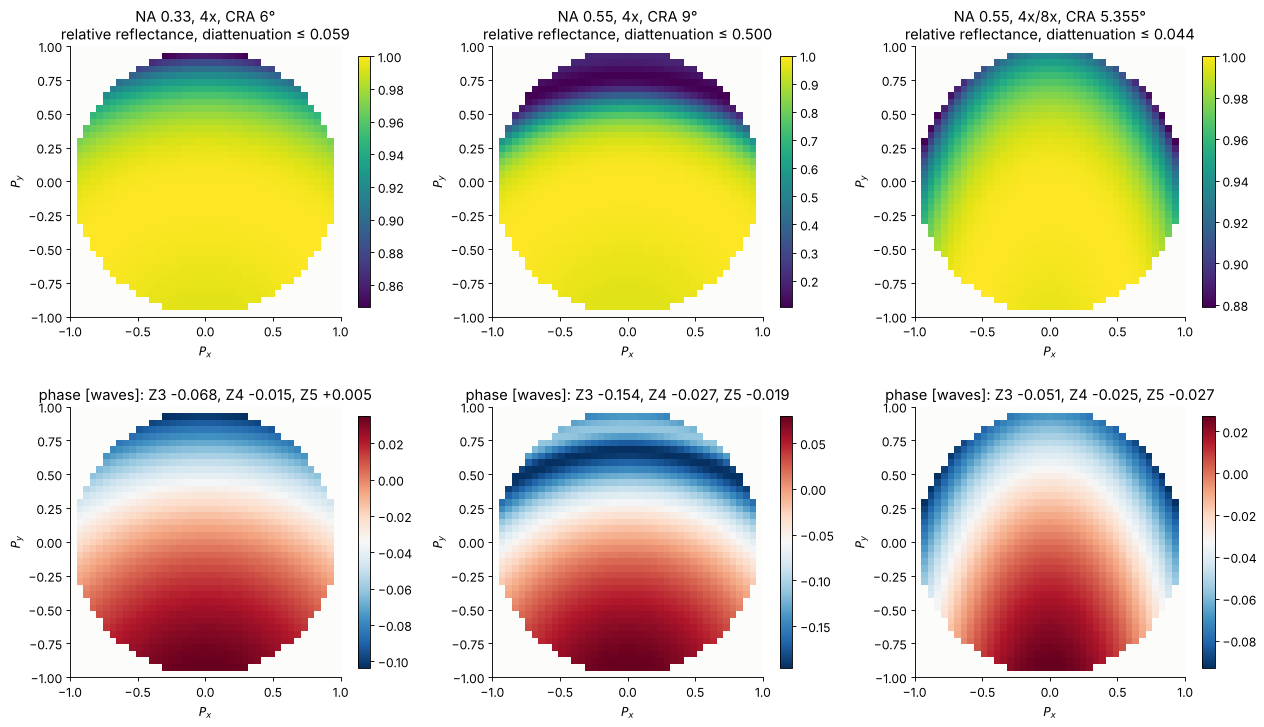

In [4]:
z_eff = ml.effective_depth(6*DEG)
print(f"effective mirror plane {z_eff:.1f} nm below the top of the stack (s), "
      f"{ml.effective_depth(6*DEG, pol='p'):.1f} nm (p); the stack is {ml.thickness:.0f} nm thick")

N_p = 41
p = np.linspace(-1, 1, N_p)
PX, PY = np.meshgrid(p, p)
inside = np.hypot(PX, PY) < 0.999
cases = [("NA 0.33, 4x, CRA 6°", 0.33, (4, 4), 6.0),
         ("NA 0.55, 4x, CRA 9°", 0.55, (4, 4), 9.0),
         ("NA 0.55, 4x/8x, CRA 5.355°", 0.55, (4, 8), 5.355)]
fig, axes = plt.subplots(2, 3, figsize=(16, 9.4))
for k, (name, NA, (Mx, My), cra) in enumerate(cases):
    mlk = euv.Multilayer.design(LAM, cra*DEG)
    J = mlk.jones(NA*PX/Mx, np.sin(cra*DEG) + NA*PY/My)     # incidence of the source points
    J0 = mlk.jones(0.0, np.sin(cra*DEG))
    d = jones_pupil.decompose(J/np.sqrt(np.sum(abs(J0)**2)/2))
    T = np.where(inside, d["transmission"], np.nan)
    phase = np.where(inside, np.angle(np.exp(1j*(d["phase"] - d["phase"][N_p//2, N_p//2]))), np.nan)
    dia = np.where(inside, np.hypot(d["diattenuation"][0], d["diattenuation"][1]), np.nan)
    im = axes[0, k].imshow(T, extent=(-1, 1, -1, 1), origin="lower", cmap="viridis")
    fig.colorbar(im, ax=axes[0, k], shrink=0.8)
    axes[0, k].set_title(f"{name}\nrelative reflectance, diattenuation ≤ {np.nanmax(dia):.3f}")
    im = axes[1, k].imshow(phase/(2*np.pi), extent=(-1, 1, -1, 1), origin="lower", cmap="RdBu_r")
    fig.colorbar(im, ax=axes[1, k], shrink=0.8)
    z = jones_pupil.fit_zernikes(PX[inside], PY[inside], phase[inside]/(2*np.pi), n_terms=9)
    axes[1, k].set_title(f"phase [waves]: Z3 {z[3]:+.3f}, Z4 {z[4]:+.3f}, Z5 {z[5]:+.3f}")
    print(f"{name}: reflectance {np.nanmin(T):.3f} to {np.nanmax(T):.3f} of the chief ray, "
          f"phase Zernikes Z2..Z9 [waves]: " + " ".join(f"{z[j]:+.3f}" for j in range(2, 10)))
for ax in axes.ravel():
    ax.grid(False); ax.set_xlabel("$P_x$"); ax.set_ylabel("$P_y$")
fig.tight_layout()

The effective mirror lies about 46 nm (s) to 50 nm (p) below the top,
deeper than the absorber is thick. At NA 0.33 (mask-side NA 0.083 around 6°)
the blank costs up to 17 % of reflectance at the top of the pupil (the
side that leaves the mask at the steepest angle, 10.7°). Its phase is
almost a pure tilt, $Z_3$ = −0.07 waves, which moves the image by
$Z_3\lambda/\mathrm{NA}$ ≈ 2.8 nm in y, the pattern shift of section 7. A
little $Z_4$ (focus) and $Z_5$ (astigmatism) are left. The diattenuation
stays below 7 %.

An isotropic NA 0.55 projector with 4x would need a CRA of about 9° (see
notebook 157, EUV projector and pupil), and then the top of the pupil
meets the blank beyond its angular band: the reflectance there drops to
10 %, the phase tilt doubles and the diattenuation reaches 50 %. The
anamorphic projector with 8x in y halves the angles in the plane of
incidence and keeps the blank as benign as at NA 0.33. This is one of the
two reasons for the anamorphic design.

## 4. The absorber

The absorber must make the dark parts of the mask dark, after two passes
through it. TaBN (about 60 nm, with a thin oxide anti-reflection layer on
top in practice) is the standard. A **low-n** absorber (n ≈ 0.90, here a
model material) absorbs about as strongly but shifts the phase much more
per nanometre: at about half the thickness it reflects some 19 % with a
phase of 180°, an attenuated phase shift mask (see notebook 37, mask models compared). Nickel absorbs twice as strongly as TaBN and could be
thinner still, but it is hard to etch. The curves are for laterally
infinite films (`ReflectiveMask.jones()`); the swings come from
interference of the absorber surface with the multilayer below.

TaBN 60 nm: R ratio 0.026, phase -179°
low-n 32 nm: R ratio 0.189, phase -182°
Ni 40 nm: R ratio 0.001, phase -51°


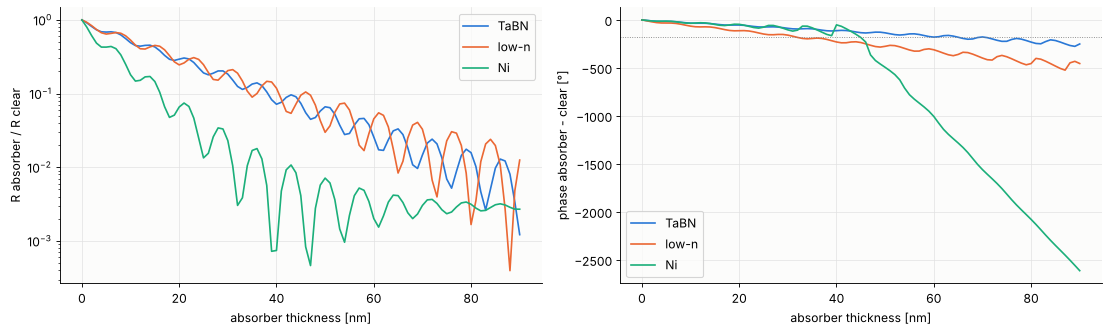

In [5]:
t = np.linspace(0, 90, 91)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
summary = {}
for name, col in (("TaBN", BLUE), ("low-n", ORANGE), ("Ni", GREEN)):
    Rr, ph = [], []
    for tk in t:
        m = euv.ReflectiveMask([(name, max(tk, 1e-3))], ml)
        J_c, J_a = m.jones(np.zeros(1), np.zeros(1), 0.33, LAM, 4)
        ratio = J_a[0, 0, 0]/J_c[0, 0, 0]
        Rr.append(abs(ratio)**2); ph.append(np.angle(ratio))
    Rr, ph = np.array(Rr), np.unwrap(np.array(ph))/DEG
    summary[name] = (Rr, ph)
    axes[0].semilogy(t, Rr, color=col, label=name)
    axes[1].plot(t, ph, color=col, label=name)
axes[0].set_xlabel("absorber thickness [nm]"); axes[0].set_ylabel("R absorber / R clear")
axes[1].set_xlabel("absorber thickness [nm]"); axes[1].set_ylabel("phase absorber - clear [°]")
axes[0].legend(); axes[1].legend()
axes[1].axhline(-180, color="0.5", lw=0.8, ls=":")
fig.tight_layout()
# the low-n absorber at the thickness of a 180° phase shift (the first one)
ph_lown = summary["low-n"][1]
t_lown = float(np.round(np.interp(180.0, -ph_lown, t)))
for name, tk in (("TaBN", 60), ("low-n", t_lown), ("Ni", 40)):
    i = int(np.argmin(abs(t - tk)))
    print(f"{name} {tk:.0f} nm: R ratio {summary[name][0][i]:.3f}, phase {summary[name][1][i]:.0f}°")

The low-n absorber is taken at the thickness where its phase passes
−180°.

## 5. Shadowing: horizontal and vertical lines

The light comes in at 6° in the y-z plane (the scan direction of the
scanner). Lines along x (**horizontal**) have their edges across the
plane of incidence: each absorber line throws a shadow of $t\tan 6°$
onto the multilayer on the way in and blocks the same on the way out,
together $2t\tan 6°$ = 12.6 nm at the mask or 3.2 nm on the wafer for
60 nm of TaBN. Lines along y (**vertical**) see the oblique light along
their length and hardly any shadow. The Kirchhoff mask
(`ReflectiveMask.kirchhoff()`, the film reflections at the chief ray
assigned to the regions) knows no orientation. 16 nm dark lines at a pitch of
32 nm, NA 0.33, a dipole across the lines (σ 0.55 to 0.9):

shadow of a 60 nm absorber at 6°: 12.6 nm at the mask, 3.2 nm at the wafer



mask         pitch  NILS V NILS H  CD H - CD V at the dose of V
TaBN 60 nm      32    2.63   2.39                         +3.06 nm


TaBN 60 nm      48    2.70   2.65                         +4.01 nm


TaBN 60 nm      64    2.75   2.84                         +3.30 nm


low-n 32 nm     32    2.46   2.14                         +2.66 nm


low-n 32 nm     48    2.37   2.11                         +2.91 nm


low-n 32 nm     64    2.25   2.18                         +1.05 nm


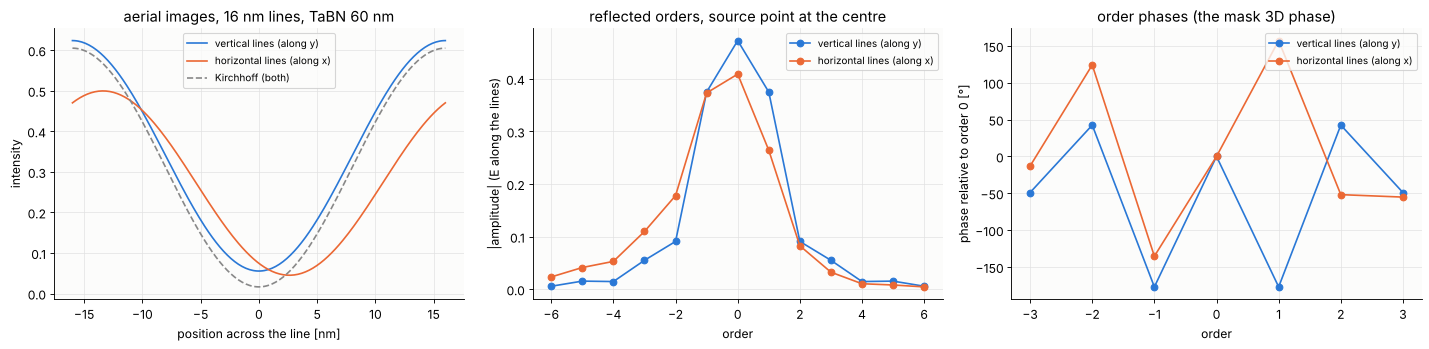

In [6]:
P033 = Projector(0.33, LAM, magnification=4)
tabn = euv.ReflectiveMask([("TaBN", 60.0)], ml, name="TaBN 60 nm")
lown = euv.ReflectiveMask([("low-n", t_lown)], ml, name=f"low-n {t_lown:.0f} nm")
print("shadow of a 60 nm absorber at 6°:", f"{euv.shadow_width(60.0):.1f} nm at the mask,",
      f"{euv.shadow_width(60.0)/4:.1f} nm at the wafer")


def lines(pitch, orientation, mask, sigma=(0.9, 0.55)):
    """Lines and spaces 1:1, dark lines (absorber) on a bright field, with a
    dipole across the lines."""
    axis = "x" if orientation == "y" else "y"
    return LithoSimulation(MaskLayout.lines_spaces(pitch, pitch/2, orientation=orientation), mask,
                           Illumination.dipole(sigma[0], sigma[1], axis=axis, n_samples=21), P033)


def threshold_to_size(u, I, center, cd):
    """Threshold at which the dark line prints at cd."""
    ts = np.linspace(I.min() + 1e-3, I.max() - 1e-3, 400)
    e = np.array([metrics.threshold_cd(u, I, th, center) - cd for th in ts])
    ok = np.isfinite(e)
    o = np.argsort(e[ok])
    return float(np.interp(0.0, e[ok][o], ts[ok][o]))


pitch = 32.0
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for orient, col, lab in (("y", BLUE, "vertical lines (along y)"), ("x", ORANGE, "horizontal lines (along x)")):
    sim = lines(pitch, orient, tabn)
    u, I = sim.cut(201)
    u0 = u - sim.cut_coordinates(201)[1]
    axes[0].plot(u0, I, color=col, label=lab)
    m = np.arange(-6, 7)
    s0 = np.zeros(1)
    if orient == "y":
        J = tabn.order_jones(sim.layout, m, [0], s0, s0, 0.33, LAM, 4)[0, :, :, 0, :]
    else:
        J = tabn.order_jones(sim.layout, [0], m, s0, s0, 0.33, LAM, 4)[0, :, :, :, 0]
    amp = np.abs(J[0, 0]) if orient == "x" else np.abs(J[1, 1])    # E along the lines
    ph = np.angle(J[0, 0] if orient == "x" else J[1, 1])
    axes[1].plot(m, amp, "o-", color=col, label=lab)
    rel = np.angle(np.exp(1j*(ph - ph[m == 0])))/DEG
    axes[2].plot(m[abs(m) <= 3], rel[abs(m) <= 3], "o-", color=col, label=lab)
simk = lines(pitch, "y", tabn.kirchhoff())
u, I = simk.cut(201)
axes[0].plot(u - simk.cut_coordinates(201)[1], I, color=GREY, ls="--", label="Kirchhoff (both)")
axes[0].set_xlabel("position across the line [nm]"); axes[0].set_ylabel("intensity")
axes[0].legend(fontsize=9); axes[0].set_title(f"aerial images, {pitch/2:.0f} nm lines, TaBN 60 nm")
axes[1].set_xlabel("order"); axes[1].set_ylabel("|amplitude| (E along the lines)")
axes[1].set_title("reflected orders, source point at the centre"); axes[1].legend(fontsize=9)
axes[2].set_xlabel("order"); axes[2].set_ylabel("phase relative to order 0 [°]")
axes[2].set_title("order phases (the mask 3D phase)"); axes[2].legend(fontsize=9)
fig.tight_layout()

# H-V bias: same mask CD, dose (threshold) set by the vertical lines
print(f"\n{'mask':12s} {'pitch':>5s}  {'NILS V':>6s} {'NILS H':>6s}  {'CD H - CD V at the dose of V':>28s}")
for mask in (tabn, lown):
    for pitch in (32.0, 48.0, 64.0):
        res = {}
        for orient in ("y", "x"):
            sim = lines(pitch, orient, mask)
            u, c = sim.cut_coordinates(401)[:2]
            res[orient] = (u, sim.cut(401)[1], c)
        th = threshold_to_size(*res["y"], pitch/2)
        cd = {o: metrics.threshold_cd(r[0], r[1], th, r[2]) for o, r in res.items()}
        nils = {o: metrics.nils_at_threshold(r[0], r[1], th, r[2]) for o, r in res.items()}
        print(f"{mask.name:12s} {pitch:5.0f}  {nils['y']:6.2f} {nils['x']:6.2f}  {cd['x'] - cd['y']:+28.2f} nm")

The horizontal lines have lost contrast and moved: their image is
asymmetric and shifted by about 2.5 nm in y. The diffraction orders show
why. The absorber of the vertical lines diffracts symmetrically (equal
amplitudes, the phases of $\pm m$ equal). That of the horizontal lines does
not: the shadowed side weakens the orders on one side, and the order
phases grow linearly with the order number (a tilt, the shift) plus a
curvature (a focus). The phase errors of a few tens of degrees in the
orders that pass the pupil are the **mask 3D phase**, which a thin mask model
cannot have.

At the same dose the horizontal lines print 3 to 4 nm wider than the
vertical ones for TaBN, about the geometric shadow. This **H-V bias** is
corrected on the mask (OPC), but it costs contrast that no bias returns.
The thinner low-n absorber throws a smaller shadow (1 to 3 nm of bias).
Here it also has less NILS than TaBN, because the 19 % it reflects at 180°
raise the dark level of these dark lines in a bright field. It pays off
for features that print as the bright tone (contacts, trenches), as
attenuated phase shift masks do in DUV.

## 6. Best focus through pitch

The order phases of section 5 include a curvature, which acts like a
defocus and depends on which orders pass the pupil, i.e. on the pitch.
The best focus (the peak of the NILS through focus) therefore moves with
the pitch, for both orientations, since the effective mirror plane and the
absorber thickness act on both. With a thin mask it stays at zero.

54 focus series in 18 s
TaBN 60 nm             y: best focus  -46.9 to   -7.4 nm, range  39.4 nm
TaBN 60 nm             x: best focus  -43.4 to   -9.7 nm, range  33.7 nm
low-n 32 nm            y: best focus  -54.4 to   -3.7 nm, range  50.7 nm
low-n 32 nm            x: best focus  -60.0 to   -5.3 nm, range  54.7 nm
Kirchhoff TaBN 60 nm   y: best focus   -0.6 to   -0.3 nm, range   0.3 nm
Kirchhoff TaBN 60 nm   x: best focus   -0.6 to   -0.3 nm, range   0.3 nm


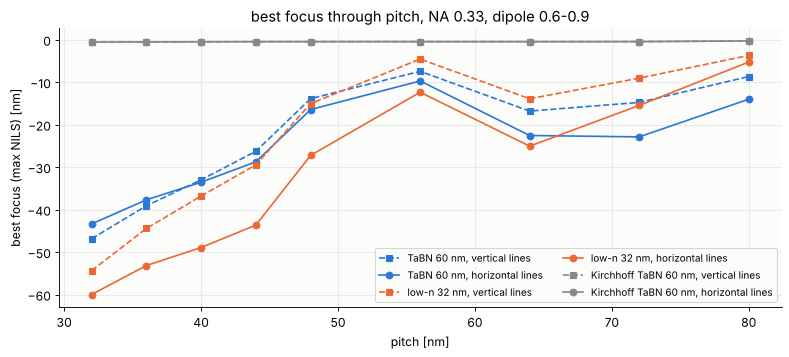

In [7]:
pitches = np.array([32.0, 36.0, 40.0, 44.0, 48.0, 56.0, 64.0, 72.0, 80.0])
foci = np.linspace(-90, 90, 19)


def through_focus(sim, pitch):
    """NILS, CD and feature centre through focus at the threshold that sizes
    the line at focus 0."""
    u, c = sim.cut_coordinates(201)[:2]
    I = sim._cuts(201, 1.0, None, foci, 0.0)[1]
    th = threshold_to_size(u, I[len(foci)//2], c, pitch/2)
    nils = np.array([metrics.nils_at_threshold(u, Ii, th, c) for Ii in I])
    centre = np.array([euv.feature_center(u, Ii, th, c) for Ii in I]) - c
    return nils, centre


t0 = time.time()
bf = {}
data = {}
for mask in (tabn, lown, tabn.kirchhoff()):
    for orient in ("y", "x"):
        vals = []
        for pitch in pitches:
            sim = lines(pitch, orient, mask, sigma=(0.9, 0.6))
            nils, centre = through_focus(sim, pitch)
            data[mask.name if hasattr(mask, "name") else "K", orient, pitch] = (nils, centre)
            vals.append(metrics.best_focus(foci, nils, n_fit=9))
        bf[mask.name, orient] = np.array(vals)
print(f"{len(pitches)*6} focus series in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(10, 4.6))
for (name, orient), v in bf.items():
    col = {tabn.name: BLUE, lown.name: ORANGE}.get(name, GREY)
    ax.plot(pitches, v, "o-" if orient == "x" else "s--", color=col,
            label=f"{name}, {'horizontal' if orient == 'x' else 'vertical'} lines")
ax.set_xlabel("pitch [nm]"); ax.set_ylabel("best focus (max NILS) [nm]")
ax.legend(fontsize=9, ncol=2); ax.set_title("best focus through pitch, NA 0.33, dipole 0.6-0.9")
fig.tight_layout()
for key, v in bf.items():
    print(f"{key[0]:22s} {key[1]}: best focus {np.nanmin(v):6.1f} to {np.nanmax(v):6.1f} nm, "
          f"range {np.nanmax(v) - np.nanmin(v):5.1f} nm")

With TaBN the best focus moves by 35 to 40 nm between the dense lines and the
pitches near 56 nm, a large part of the depth of focus of these lines
(about 100 nm). One focus for all pitches of a layer is therefore a
compromise, and source optimization and OPC for EUV take the mask 3D phase
into account. Low-n absorbers were proposed to shrink this range, with a
thickness and index chosen so that the phase of the absorber and of the
multilayer cancel. In this model, with this dipole and at the thickness of a
180° phase, the low-n absorber does not do better (range about 50 nm):
the benefit depends on n, k, the thickness and the source, which is why
the choice of absorber is a mask 3D optimization of its own (Erdmann et al.).

## 7. Pattern shift and telecentricity

The shift of the horizontal lines at focus and its change through focus
(the slope, a telecentricity error, in nm per nm = rad) for the same
series:

TaBN 60 nm: shift at focus 2.36 to 3.14 nm, telecentricity -32 to -12 mrad
low-n 32 nm: shift at focus 2.31 to 3.52 nm, telecentricity -38 to -13 mrad


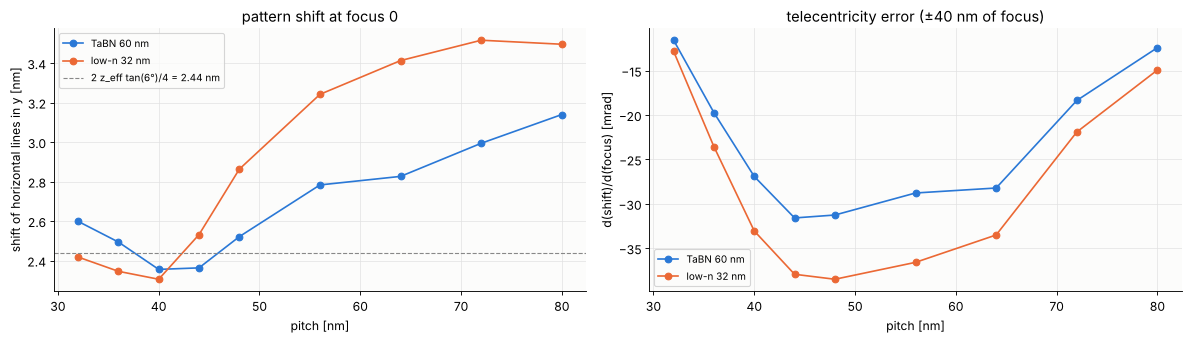

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
near = abs(foci) <= 40
for name, col in ((tabn.name, BLUE), (lown.name, ORANGE)):
    shift, tele = [], []
    for pitch in pitches:
        nils, centre = data[name, "x", pitch]
        ok = near & np.isfinite(centre)
        a, b = np.polyfit(foci[ok], centre[ok], 1)
        shift.append(b); tele.append(1e3*a)
    axes[0].plot(pitches, shift, "o-", color=col, label=name)
    axes[1].plot(pitches, tele, "o-", color=col, label=name)
    print(f"{name}: shift at focus {min(shift):.2f} to {max(shift):.2f} nm, "
          f"telecentricity {min(tele):.0f} to {max(tele):.0f} mrad")
geo = 2*z_eff*np.tan(6*DEG)/4
axes[0].axhline(geo, color=GREY, ls="--", lw=1, label=f"2 z_eff tan(6°)/4 = {geo:.2f} nm")
axes[0].set_xlabel("pitch [nm]"); axes[0].set_ylabel("shift of horizontal lines in y [nm]")
axes[0].legend(fontsize=9); axes[0].set_title("pattern shift at focus 0")
axes[1].set_xlabel("pitch [nm]"); axes[1].set_ylabel("d(shift)/d(focus) [mrad]")
axes[1].legend(fontsize=9); axes[1].set_title("telecentricity error (±40 nm of focus)")
fig.tight_layout()

The lines shift by 2.3 to 3.5 nm in y. The dashed line is the shift of a
mirror at the effective depth: lit at 6°, the reflection comes from a
plane 46 nm below the top, which moves the image of the mask by
$2z_\mathrm{eff}\tan 6°$ = 9.8 nm at the mask or 2.4 nm on the wafer. The
pitch-dependent part on top of that (up to 1 nm) is the one that matters:
a uniform shift is taken up by the alignment, a shift that differs
between the pitches of one layer is an overlay error.

Through focus the lines move by 12 to 40 mrad, a few tenths of a
nanometre per 10 nm of focus. The two poles of the dipole are reflected
and shadowed differently, and the image of an unbalanced dipole walks
sideways with the focus. On a real wafer, where focus varies with the
topography, this becomes overlay too.

## 8. Summary

- At 13.5 nm all materials absorb and $n \approx 1$. A Mo/Si multilayer
  of 40 pairs (period 6.94 nm, Γ ≈ 0.4, Ru cap) reflects 73 % in theory and
  about 70 % with interface mixing, over a band of 0.7 nm and up to about
  10° of incidence.
- Over the mask-side cone the blank is a Jones pupil: an apodization of up
  to 17 % at NA 0.33, a phase tilt (an effective mirror plane 46 nm deep)
  and little diattenuation. An isotropic NA 0.55 projector would push the
  blank out of its angular band; the anamorphic 8x direction avoids that.
- The reflective mask lit at 6° is a mask 3D problem. Horizontal lines
  print 3 to 4 nm wider than vertical ones (shadowing, about
  $2t\tan 6°/M$), the best focus moves by 35 to 40 nm through pitch with
  TaBN, the pattern shifts by about 2.5 nm (the effective mirror plane)
  with up to 1 nm that depends on the pitch, and the image moves through
  focus by 10 to 40 mrad.
- Thinner absorbers (low-n) reduce the shadow and act as attenuated phase
  shifters. Whether they also reduce the best focus range depends on the
  material, the thickness and the source.
- The tools: `litho.euv.Multilayer`, `ReflectiveMask` (any `LithoSimulation`
  with 1D layouts; anamorphic magnifications too), `kirchhoff()`,
  `effective_depth()`, `shadow_width()`, `feature_center()`.

In [9]:
print(f"run time {time.time() - t_start:.0f} s")

run time 52 s
